# **Initialization**

In [1]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import seaborn as sns
import glob as glob
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils import resample

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, Flatten, BatchNormalization, LeakyReLU
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 1. Data Loading and Preprocessing
path = "/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets" # use your path
files = [file for file in glob.glob(path + "**/*.csv", recursive=True)]

[print(f) for f in files]

data = [pd.read_csv(f) for f in files]

/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv
/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv


In [3]:
# Remove duplicate data
data = pd.concat([d for d in data]).drop_duplicates(keep=False)
data.reset_index(drop=True, inplace = True)
data.shape

(257673, 45)

In [4]:
# Check dataset content and shape
data.shape
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  si

In [5]:
# Select all columns with "object" data type
obj_df = data.select_dtypes(include=['object']).copy()
obj_df.head()

,proto,service,state,attack_cat
0,udp,-,INT,Normal
1,udp,-,INT,Normal
2,udp,-,INT,Normal
3,udp,-,INT,Normal
4,udp,-,INT,Normal


In [6]:
# Convert "object" columns and drop originals
obj_df["proto"] = obj_df["proto"].astype('category')
obj_df["service"] = obj_df["service"].astype('category')
obj_df["state"] = obj_df["state"].astype('category')
obj_df["attack_cat"] = obj_df["attack_cat"].astype('category')
obj_df.dtypes

obj_df["proto_cat"] = obj_df["proto"].cat.codes
obj_df["service_cat"] = obj_df["service"].cat.codes
obj_df["state_cat"] = obj_df["state"].cat.codes
obj_df["attack_cat_cat"] = obj_df["attack_cat"].cat.codes

data["proto"]=obj_df["proto_cat"]
data["service"]=obj_df["service_cat"]
data["state"]=obj_df["state_cat"]
data["attack_cat"]=obj_df["attack_cat_cat"]

df = data.drop(data.columns[0],axis=1)

In [7]:
# Re-check dataset content & shape
df.groupby('label').agg({'label':'first', 'label':'count'}).rename_axis(None).sort_values('label', ascending=False)

,label
1,164673
0,93000


In [8]:
# Separate features and labels
X = data.drop(['label', 'attack_cat'], axis=1)
y = data['label']

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y)

np.unique(y)

array([0, 1])

In [ ]:
# Separate features and labels (ensure attack_cat is dropped to avoid target leakage)
X = data.drop(['label', 'attack_cat'], axis=1)
y = data['label']

# Split data into training and testing FIRST
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Data balancing using upsampling ONLY on training data
train_data = pd.concat([X_train, y_train], axis=1)
df_majority = train_data[train_data.label == 0]
df_minority = train_data[train_data.label == 1]
df_minority_upsampled = resample(df_minority, replace=True, n_samples=len(df_majority), random_state=42)
train_data_balanced = pd.concat([df_majority, df_minority_upsampled])

X_train = train_data_balanced.drop('label', axis=1)
y_train = train_data_balanced['label']

# Normalize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define num_classes
num_classes = len(np.unique(y_train))

# Reshape data for CNN-LSTM (Note: shape is 42 features instead of 43)
y_train = to_categorical(y_train, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


# **CNN Architecture**

In [ ]:
# 2. Build Enhanced CNN-LSTM Model
def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="Enhanced_CNN_LSTM")

    # CNN Block 1
    model.add(Conv1D(64, 3, input_shape=(42, 1)))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # CNN Block 2
    model.add(Conv1D(64, 1))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # CNN Block 3
    model.add(Conv1D(64, 1))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # Fully connected layers with regularization
    model.add(Flatten())
    model.add(Dense(64, input_dim=2))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Dense(32))
    model.add(LeakyReLU(alpha=0.1))

    # Output layer
    model.add(Dense(2, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1], 1)
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_enhanced_model.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

In [ ]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

In [ ]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_enhanced_model.keras')

# Predict on testing data
y_pred = (model.predict(X_test) > 0.5).astype("int32")

#  Get predicted labels for multiclass
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack'], digits=4))

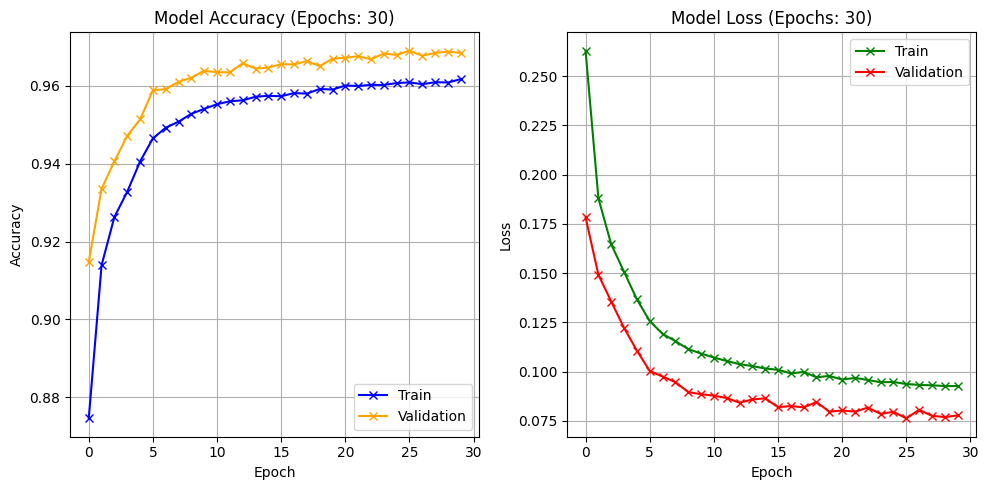

In [25]:
# Memvisualisasikan hasil training model dengan informasi epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# **CNN-LSTM Architecture**

In [ ]:
# 2. Build Enhanced CNN-LSTM Model
def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="Enhanced_CNN_LSTM")

    # CNN Block 1
    model.add(Conv1D(filters=128, kernel_size=3, activation='relu',
                    input_shape=input_shape,
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.4))

    # CNN Block 2
    model.add(Conv1D(filters=128, kernel_size=2, activation='relu',
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.4))

    # CNN Block 3
    model.add(Conv1D(filters=64, kernel_size=1, activation='relu',
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))

    # Lapisan LSTM yang Diperkuat
    model.add(LSTM(128, return_sequences=True,
                 kernel_regularizer=l2(0.001)))
    model.add(Dropout(0.5))
    model.add(LSTM(64))
    model.add(Dropout(0.5))

    # Fully connected layers with regularization
    model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.5))

    model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1], 1)
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_enhanced_model.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

In [ ]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_enhanced_model.keras')

# Predict on testing data
y_pred = (model.predict(X_test) > 0.5).astype("int32")

#  Get predicted labels for multiclass
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack'], digits=4))

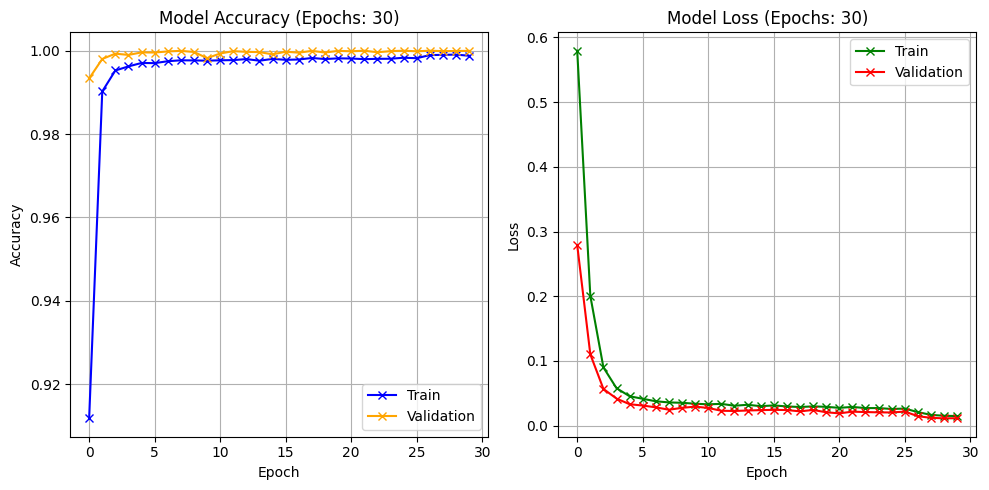

In [ ]:
# Memvisualisasikan hasil training model dengan informasi epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# **LSTM Architecture**

In [13]:
# 2. Build Enhanced CNN-LSTM Model
def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="Enhanced_CNN_LSTM")

    # Reshape input for LSTM
    model.add(tf.keras.layers.Reshape((input_shape[0], 1), input_shape=input_shape))

    # Lapisan LSTM yang Diperkuat
    model.add(LSTM(128, return_sequences=True,
                 kernel_regularizer=l2(0.001)))
    model.add(Dropout(0.5))
    model.add(LSTM(64))
    model.add(Dropout(0.5))

    # Fully connected layers with regularization
    model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.5))

    model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1],) # Correct input shape for reshape layer
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_enhanced_model.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

In [ ]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_enhanced_model.keras')

# Predict on testing data
y_pred = (model.predict(X_test) > 0.5).astype("int32")

#  Get predicted labels for multiclass
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack']))

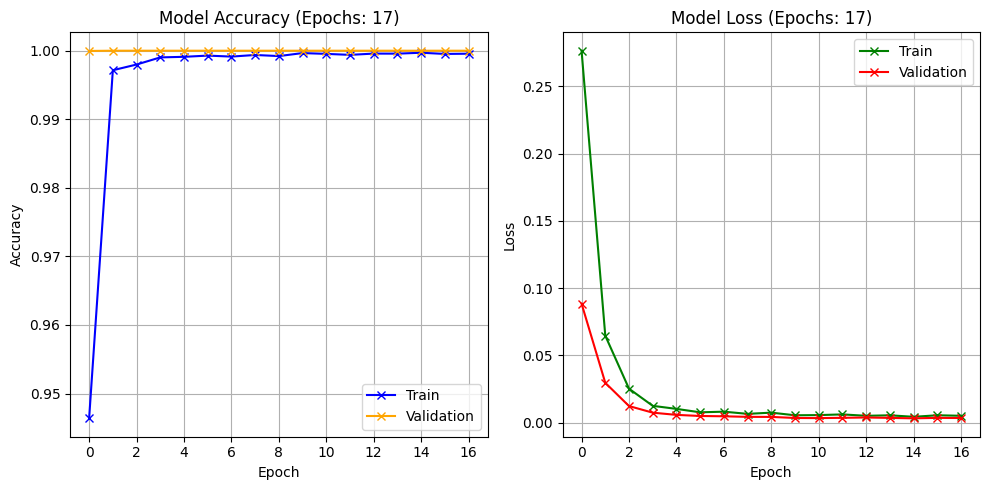

In [18]:
# Memvisualisasikan hasil training model dengan informasi epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()